# Phase 2f: Deep Learning IDS - LSTM (PyTorch)
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Architecture follows the reference paper: the feature vector is treated as a sequence of length F with one value per step, then `LSTM(50) -> Dropout(0.2) -> Dense(1, sigmoid)`.
Trains on the **balanced** training set, early-stops on the validation loss, and evaluates on the **untouched** test set.

**Why PyTorch:** in Phase 3, FGSM and PGD need the gradient of the loss with respect to the input features. PyTorch makes that a few lines of code.

## Step 0: Install, import and settings

In [ ]:
# Run once if needed (CPU version):
# %pip install torch


In [1]:
import os, json, time, copy
import numpy as np
import joblib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, classification_report)

DATA_DIR = "data/processed"
MODEL_DIR = "models"
RESULT_DIR = "results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ---- Training settings ----
EPOCHS = 15            # paper uses 50; early stopping usually stops sooner
BATCH_SIZE = 512       # paper uses 32; larger batches are much faster on CPU
LR = 1e-3
PATIENCE = 3           # stop if val loss does not improve for this many epochs
TRAIN_SAMPLE = None    # e.g. 100_000 for a quick test run; None = use all training data
SEED = 42

torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

needed = ["X_train_bal.npy", "y_train_bal_binary.npy", "X_val.npy", "y_val_binary.npy",
          "X_test.npy", "y_test_binary.npy"]
missing = [f for f in needed if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(f"Missing in '{os.path.abspath(DATA_DIR)}': {missing}. "
                            "Run Phase 1 and Phase 1b, or fix DATA_DIR.")
print("All data files found")

Device: cpu
All data files found


## Step 1: Load data

In [2]:
X_train = np.load(f"{DATA_DIR}/X_train_bal.npy")
y_train = np.load(f"{DATA_DIR}/y_train_bal_binary.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy");  y_val  = np.load(f"{DATA_DIR}/y_val_binary.npy")
X_test  = np.load(f"{DATA_DIR}/X_test.npy"); y_test = np.load(f"{DATA_DIR}/y_test_binary.npy")

if TRAIN_SAMPLE:
    idx = np.random.RandomState(SEED).choice(len(X_train), TRAIN_SAMPLE, replace=False)
    X_train, y_train = X_train[idx], y_train[idx]

N_FEATURES = X_train.shape[1]
for n, X, y in [("train (balanced)", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{n:17s} X={X.shape}  attack ratio={y.mean():.3f}")

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.float32))),
    batch_size=BATCH_SIZE, shuffle=True)

train (balanced)  X=(694088, 70)  attack ratio=0.712
val               X=(378120, 70)  attack ratio=0.169
test              X=(378120, 70)  attack ratio=0.169


## Step 2: Define the LSTM model
The model takes a flat feature vector `(batch, F)` and reshapes it internally to `(batch, F, 1)`. Keeping the input flat makes the Phase 3 attacks simple. It outputs a logit; the sigmoid is applied at prediction time.

In [3]:
class LSTMIDS(nn.Module):
    def __init__(self, hidden=50, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):                 # x: (B, F)
        x = x.unsqueeze(-1)               # (B, F, 1)
        _, (h, _) = self.lstm(x)          # h: (1, B, hidden)
        return self.fc(self.drop(h[-1])).squeeze(-1)   # logits: (B,)

model = LSTMIDS().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params:,}")

LSTMIDS(
  (lstm): LSTM(1, 50, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=50, out_features=1, bias=True)
)
Trainable parameters: 10,651


## Step 3: Helper functions

In [4]:
criterion = nn.BCEWithLogitsLoss()

@torch.no_grad()
def predict_proba(model, X, bs=4096):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(device)
        out.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def eval_loss(model, X, y, bs=4096):
    model.eval()
    total = 0.0
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(device)
        yb = torch.from_numpy(y[i:i + bs].astype(np.float32)).to(device)
        total += criterion(model(xb), yb).item() * len(xb)
    return total / len(X)

def evaluate(y_true, y_prob, name):
    y_pred = (y_prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    m = {
        "split": name,
        "accuracy":    accuracy_score(y_true, y_pred),
        "precision":   precision_score(y_true, y_pred, zero_division=0),
        "recall":      recall_score(y_true, y_pred),
        "f1":          f1_score(y_true, y_pred),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "fnr":         fn / (fn + tp),
        "roc_auc":     roc_auc_score(y_true, y_prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return m, y_pred

## Step 4: Train with early stopping
Expect several minutes per epoch on CPU. For a quick test, set `TRAIN_SAMPLE = 100_000` in Step 0 and rerun from Step 1.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val, best_state, wait = float("inf"), None, 0

t_start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb); n += len(xb)

    tr_loss = running / n
    va_loss = eval_loss(model, X_val, y_val)
    va_acc = accuracy_score(y_val, (predict_proba(model, X_val) >= 0.5).astype(int))
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss); history["val_acc"].append(va_acc)
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} | val acc {va_acc:.4f} | {time.time()-t_start:.0f}s")

    if va_loss < best_val - 1e-5:
        best_val, best_state, wait = va_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

train_time = time.time() - t_start
model.load_state_dict(best_state)
torch.save({"state_dict": best_state, "n_features": N_FEATURES}, f"{MODEL_DIR}/lstm_baseline.pt")
print(f"\nTotal training time: {train_time/60:.1f} min | best val loss: {best_val:.4f}")

Epoch  1/15 | train loss 0.4460 | val loss 0.6553 | val acc 0.6651 | 389s
Epoch  2/15 | train loss 0.3493 | val loss 0.8009 | val acc 0.6624 | 917s
Epoch  3/15 | train loss 0.5360 | val loss 1.0186 | val acc 0.1689 | 1774s
Epoch  4/15 | train loss 0.5411 | val loss 0.6802 | val acc 0.7178 | 1921s
Early stopping at epoch 4

Total training time: 32.0 min | best val loss: 0.6553


## Step 5: Learning curves

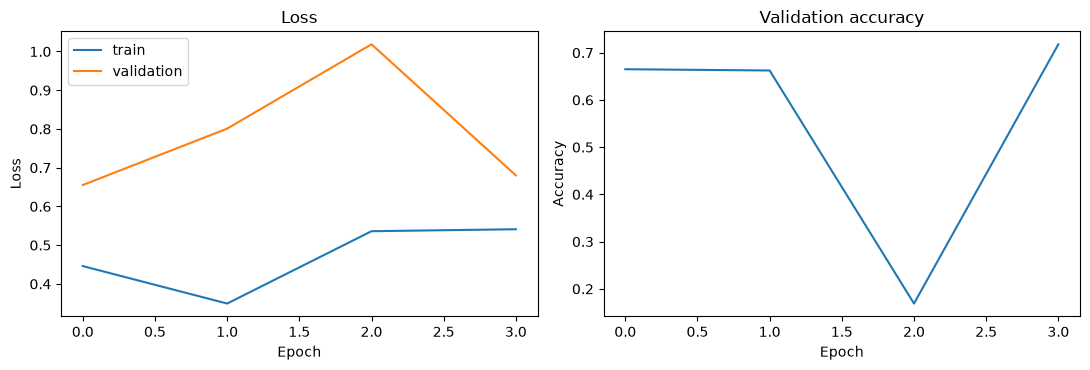

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["val_acc"]); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title("Validation accuracy")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/lstm_learning_curves.png", dpi=150)
plt.show()

## Step 6: Results on validation and test sets

In [7]:
val_prob  = predict_proba(model, X_val)
test_prob = predict_proba(model, X_test)
val_m,  val_pred  = evaluate(y_val,  val_prob,  "validation")
test_m, test_pred = evaluate(y_test, test_prob, "test")

keys = ["accuracy", "precision", "recall", "f1", "specificity", "fpr", "fnr", "roc_auc"]
print(f"{'Metric':14s} {'Validation':>12s} {'Test':>12s}")
for k in keys:
    print(f"{k:14s} {val_m[k]:12.4f} {test_m[k]:12.4f}")

# Inference latency (the reference paper reports this for fog deployment)
sample = X_test[:10000]
t0 = time.time(); _ = predict_proba(model, sample); dt = time.time() - t0
print(f"\nInference time: {dt / len(sample) * 1000:.4f} ms/sample (batched, on {device})")

print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=["Benign", "Attack"], digits=4))

Metric           Validation         Test
accuracy             0.6651       0.6663
precision            0.3324       0.3333
recall               0.9750       0.9757
f1                   0.4958       0.4969
specificity          0.6021       0.6035
fpr                  0.3979       0.3965
fnr                  0.0250       0.0243
roc_auc              0.9001       0.9017

Inference time: 0.0639 ms/sample (batched, on cpu)

Test classification report:
              precision    recall  f1-score   support

      Benign     0.9919    0.6035    0.7504    314259
      Attack     0.3333    0.9757    0.4969     63861

    accuracy                         0.6663    378120
   macro avg     0.6626    0.7896    0.6236    378120
weighted avg     0.8807    0.6663    0.7076    378120



## Step 7: Confusion matrix and ROC curve (test set)

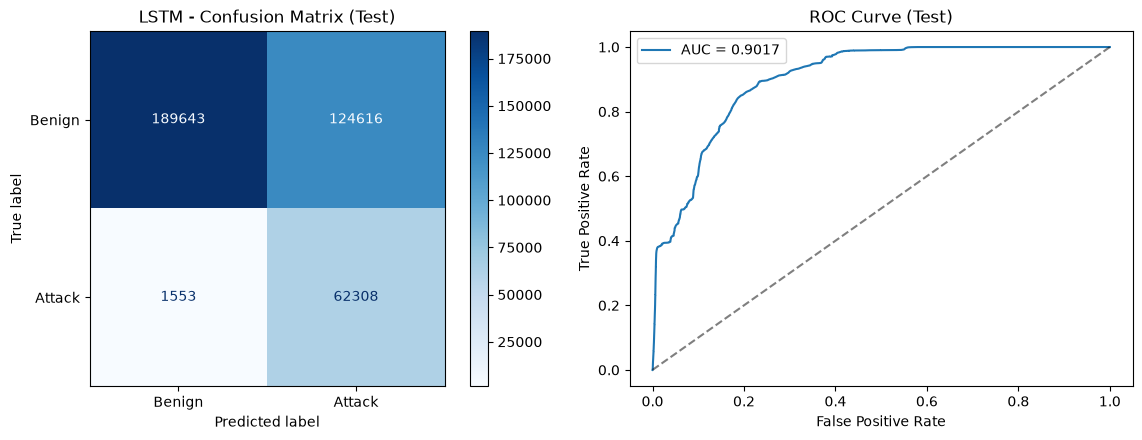

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("LSTM - Confusion Matrix (Test)")

fpr, tpr, _ = roc_curve(y_test, test_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {test_m['roc_auc']:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/lstm_clean_cm_roc.png", dpi=150)
plt.show()

## Step 8: Save results

In [9]:
with open(f"{RESULT_DIR}/lstm_clean_metrics.json", "w") as f:
    json.dump({"validation": val_m, "test": test_m, "train_time_s": train_time,
               "epochs_run": len(history["train_loss"]), "params": n_params,
               "settings": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "train_sample": TRAIN_SAMPLE}}, f, indent=2)
with open(f"{RESULT_DIR}/lstm_history.json", "w") as f:
    json.dump(history, f)
print("Saved:", sorted(os.listdir(RESULT_DIR)))

Saved: ['decision_tree_clean_cm_roc.png', 'decision_tree_clean_metrics.json', 'decision_tree_feature_importance.png', 'kmeans_clean_cm_roc.png', 'kmeans_clean_metrics.json', 'logreg_clean_cm_roc.png', 'logreg_clean_metrics.json', 'lstm_clean_cm_roc.png', 'lstm_clean_metrics.json', 'lstm_history.json', 'lstm_learning_curves.png', 'svm_clean_cm_roc.png', 'svm_clean_metrics.json', 'xgboost_clean_cm_roc.png', 'xgboost_clean_metrics.json', 'xgboost_feature_importance.png']


## Step 9: Compare with all models trained so far

In [10]:
models = {"LogReg": "logreg_clean_metrics.json", "LinSVM": "svm_clean_metrics.json",
          "XGBoost": "xgboost_clean_metrics.json", "DecTree": "decision_tree_clean_metrics.json",
          "KMeans": "kmeans_clean_metrics.json", "LSTM": "lstm_clean_metrics.json"}
res = {}
for name, fn_ in models.items():
    p = os.path.join(RESULT_DIR, fn_)
    if os.path.exists(p):
        res[name] = json.load(open(p))["test"]

print(f"{'Metric':14s}" + "".join(f"{n:>10s}" for n in res))
for k in keys:
    print(f"{k:14s}" + "".join(f"{res[n][k]:10.4f}" for n in res))

Metric            LogReg    LinSVM   XGBoost   DecTree    KMeans      LSTM
accuracy          0.7908    0.7955    0.9988    0.9983    0.6249    0.6663
precision         0.4464    0.4521    0.9931    0.9914    0.3103    0.3333
recall            0.9951    0.9938    0.9999    0.9987    0.9988    0.9757
f1                0.6163    0.6215    0.9965    0.9950    0.4735    0.4969
specificity       0.7493    0.7553    0.9986    0.9982    0.5490    0.6035
fpr               0.2507    0.2447    0.0014    0.0018    0.4510    0.3965
fnr               0.0049    0.0062    0.0001    0.0013    0.0012    0.0243
roc_auc           0.9745    0.9759    1.0000    0.9986    0.9138    0.9017


## Notes for the report and Phase 3
- The LSTM is **differentiable**, so FGSM and PGD can be applied to it directly. Use `model(x)` on a flat `(B, F)` tensor with `requires_grad=True` and take the gradient of the loss.
- **GPU note for Phase 3:** cuDNN's LSTM refuses to backpropagate while the model is in `eval()` mode. In the attack code, wrap the gradient computation in `torch.backends.cudnn.flags(enabled=False)` or keep dropout inactive by other means. On CPU this issue does not occur.
- Treating tabular flow features as a time sequence is a modelling choice made by the reference paper. The order of features is arbitrary, so mention this in the report as a limitation.